In [1]:
!pip install -q fairlearn

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference
from fairlearn.postprocessing import ThresholdOptimizer

In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]
df = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True)
df = df.dropna()

X = df.drop(columns=["income"])
y = df["income"].apply(lambda x: 1 if ">50K" in x else 0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

sex_train = X_train["sex"]
sex_test = X_test["sex"]

X_train_reduced = X_train.drop(columns=["sex"])
X_test_reduced = X_test.drop(columns=["sex"])

numeric_features = X_train_reduced.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train_reduced.select_dtypes(include=["object"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train_reduced)
X_test_encoded = preprocessor.transform(X_test_reduced)

In [4]:
base_model = LogisticRegression(max_iter=1000, random_state=42)
base_model.fit(X_train_encoded, y_train)

y_pred_base = base_model.predict(X_test_encoded)

metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate
}

mf_base = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_base,
    sensitive_features=sex_test
)

print(f"Baseline model : Logistic Regression Accuracy : {accuracy_score(y_test, y_pred_base):.2f}")
print(mf_base.by_group.round(2))

dp_diff_base = demographic_parity_difference(y_test, y_pred_base, sensitive_features=sex_test)
dp_ratio_base = demographic_parity_ratio(y_test, y_pred_base, sensitive_features=sex_test)
eo_diff_base = equalized_odds_difference(y_test, y_pred_base, sensitive_features=sex_test)

print(f"Demographic parity difference : {dp_diff_base:.2f}")
print(f"Demographic parity ratio (DI) : {dp_ratio_base:.2f}")
print(f"Equalized odds difference : {eo_diff_base:.2f}")

Baseline model : Logistic Regression Accuracy : 0.86
        accuracy  selection_rate   tpr   fpr
sex                                         
Female      0.93            0.09  0.57  0.03
Male        0.82            0.25  0.62  0.09
Demographic parity difference : 0.16
Demographic parity ratio (DI) : 0.35
Equalized odds difference : 0.07


In [10]:
to_dp = ThresholdOptimizer(
    estimator=base_model,
    constraints="demographic_parity",
    predict_method="predict_proba"
)
to_dp.fit(X_train_encoded, y_train, sensitive_features=sex_train)
y_pred_dp = to_dp.predict(X_test_encoded, sensitive_features=sex_test)
mf_dp = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_dp,
    sensitive_features=sex_test
)
dp_diff_dp = demographic_parity_difference(y_test, y_pred_dp, sensitive_features=sex_test)
eo_diff_dp = equalized_odds_difference(y_test, y_pred_dp, sensitive_features=sex_test)

In [11]:
to_eo = ThresholdOptimizer(
    estimator=base_model,
    constraints="equalized_odds",
    predict_method="predict_proba"
)
to_eo.fit(X_train_encoded, y_train, sensitive_features=sex_train)
y_pred_eo = to_eo.predict(X_test_encoded, sensitive_features=sex_test)
mf_eo = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_eo,
    sensitive_features=sex_test
)
dp_diff_eo = demographic_parity_difference(y_test, y_pred_eo, sensitive_features=sex_test)
eo_diff_eo = equalized_odds_difference(y_test, y_pred_eo, sensitive_features=sex_test)

In [12]:
comparison_df = pd.DataFrame({
    'MODEL': ['Baseline', 'TO: demographic_par.', 'TO: equalized_odds'],
    'ACC': [
        accuracy_score(y_test, y_pred_base),
        accuracy_score(y_test, y_pred_dp),
        accuracy_score(y_test, y_pred_eo)
    ],
    'SEL_M': [
        mf_base.by_group['selection_rate']['Male'],
        mf_dp.by_group['selection_rate']['Male'],
        mf_eo.by_group['selection_rate']['Male']
    ],
    'SEL_F': [
        mf_base.by_group['selection_rate']['Female'],
        mf_dp.by_group['selection_rate']['Female'],
        mf_eo.by_group['selection_rate']['Female']
    ],
    'DP_DIFF': [
        dp_diff_base,
        dp_diff_dp,
        dp_diff_eo
    ],
    'EO_DIFF': [
        eo_diff_base,
        eo_diff_dp,
        eo_diff_eo
    ]
})
display(comparison_df.round(2))

,MODEL,ACC,SEL_M,SEL_F,DP_DIFF,EO_DIFF
0,Baseline,0.86,0.25,0.09,0.16,0.07
1,TO: demographic_par.,0.83,0.17,0.18,0.01,0.35
2,TO: equalized_odds,0.84,0.19,0.11,0.08,0.03


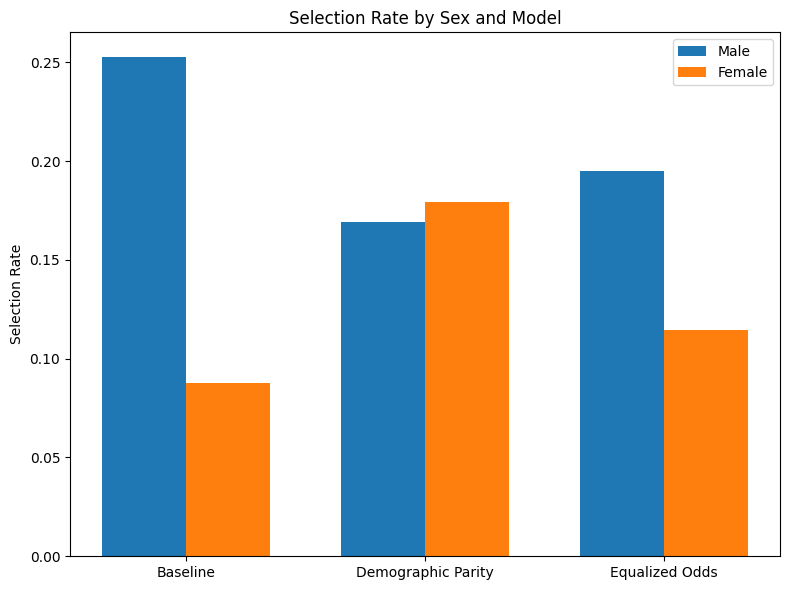

In [13]:
labels = ['Baseline', 'Demographic Parity', 'Equalized Odds']
male_rates = [comparison_df.loc[0, 'SEL_M'], comparison_df.loc[1, 'SEL_M'], comparison_df.loc[2, 'SEL_M']]
female_rates = [comparison_df.loc[0, 'SEL_F'], comparison_df.loc[1, 'SEL_F'], comparison_df.loc[2, 'SEL_F']]
x = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(x - width/2, male_rates, width, label='Male')
ax.bar(x + width/2, female_rates, width, label='Female')
ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex and Model')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.tight_layout()
plt.savefig('selection_rate_by_sex.png')
plt.show()